# 横磁場イジングモデル：基底エネルギー$E_0$

基底エネルギー$E_0$を、厳密対角化・Jordan-Wigner変換・VQEの3つの手法で求めて比較する。模型の定義は [00_model.ipynb](00_model.ipynb)、各手法のTFIMへの適用は [01_exact_diag](01_exact_diag.ipynb)・[02_jordan_wigner](02_jordan_wigner.ipynb)・[03_trotter](03_trotter.ipynb)・[04_vqe](04_vqe.ipynb)、手法の一般論は [methods/](../../methods/) を参照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 厳密対角化（src/qmb/operators.py, ed.py）と TFIM の定義（src/qmb/models.py）
from qmb.operators import plus_state
from qmb.ed import ground_state, time_evolve_expectation
from qmb.models import tfim_hamiltonian as hamiltonian, magnetization_x
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# 各手法の TFIM への適用（src/qmb/models.py, circuits.py）
from qmb.models import tfim_ground_energy_ff as ground_energy_jw, tfim_mx_quench_ff as mx_jw
from qmb.circuits import tfim_op, mx_op, plus_circuit, trotter_step, mx_trotter, vqe
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: tfim_hamiltonian??）

## 1. 厳密対角化とJordan-Wigner変換の比較

$n=2$から$10$まで、厳密対角化（$2^n\times2^n$行列）とJordan-Wigner変換（$2n\times2n$行列）で$E_0$を求め、差と計算時間を比べる。

 n   E0 (ED)          E0 (JW)          差
 2  -1.720465053409  -1.720465053409  4.4e-16
 3  -2.786586850674  -2.786586850674  4.4e-16
 4  -3.872983346207  -3.872983346207  8.9e-16
 5  -4.971328118240  -4.971328118240  0.0e+00
 6  -6.077639082402  -6.077639082402  1.8e-15
 7  -7.189581641097  -7.189581641097  1.8e-15
 8  -8.305610965881  -8.305610965881  3.6e-15


 9  -9.424632491731  -9.424632491731  5.3e-15


10  -10.545844370449  -10.545844370449  5.3e-15


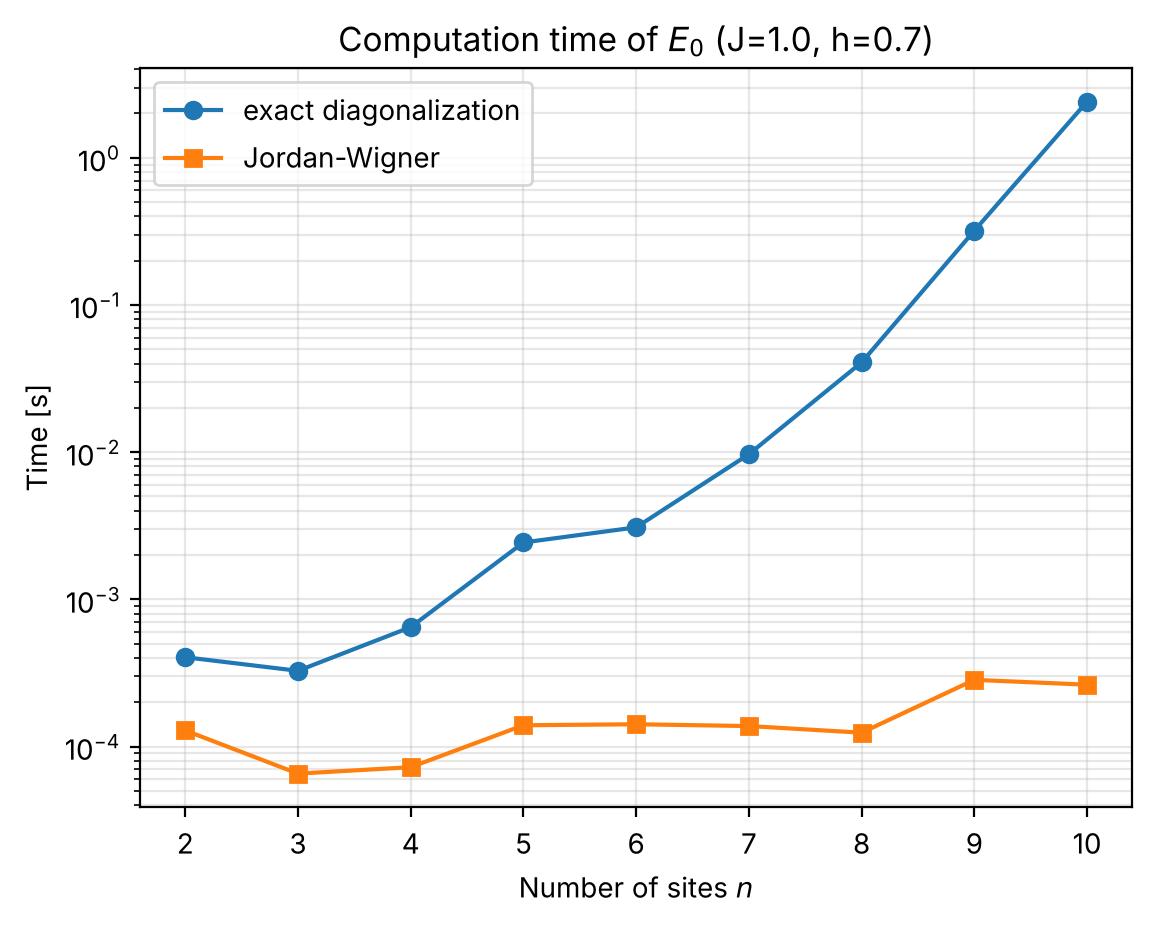

In [2]:
import time

J = 1.0
h = 0.7
ns = range(2, 11)
t_ed, t_jw = [], []
print(" n   E0 (ED)          E0 (JW)          差")
for n in ns:
    start = time.perf_counter()
    E_ed = ground_state(hamiltonian(n, J, h))[0]
    t_ed.append(time.perf_counter() - start)

    start = time.perf_counter()
    E_jw = ground_energy_jw(n, J, h)
    t_jw.append(time.perf_counter() - start)
    print(f"{n:2d}  {E_ed:.12f}  {E_jw:.12f}  {abs(E_ed - E_jw):.1e}")

plt.semilogy(list(ns), t_ed, "o-", label="exact diagonalization")
plt.semilogy(list(ns), t_jw, "s-", label="Jordan-Wigner")
plt.xlabel("Number of sites $n$")
plt.ylabel("Time [s]")
plt.title(f"Computation time of $E_0$ (J={J}, h={h})")
plt.legend()
plt.grid(which="both", alpha=0.3)
plt.show()

2つの手法の$E_0$は数値誤差の範囲（$10^{-12}$程度）で一致している。計算時間は、厳密対角化が$n$とともに指数関数的に増えるのに対し、Jordan-Wigner変換はほとんど増えない。

## 2. 大きな$n$と熱力学極限

Jordan-Wigner変換なら大きな$n$も計算できるので、1サイトあたりのエネルギー$E_0/n$が$n\to\infty$でどこに近づくかを調べる。周期境界条件で波数$k$についてフーリエ変換すると（[02_jordan_wigner.ipynb](02_jordan_wigner.ipynb)の2節の補足）、熱力学極限での値は

\begin{equation}
e_0 = \lim_{n\to\infty}\frac{E_0}{n} = -\frac{1}{2\pi}\int_{-\pi}^{\pi}\sqrt{J^2 + h^2 - 2Jh\cos k}\,dk
\end{equation}

となる。特に$h=J$では$e_0 = -4J/\pi$である。開放境界条件では、両端の分だけ$1/n$に比例するずれが加わる。

h=0.5: e0(∞) = -1.06354441,  E0/n (n=400) = -1.06136773
h=1.0: e0(∞) = -1.27323954,  E0/n (n=400) = -1.27233191
h=2.0: e0(∞) = -2.12708882,  E0/n (n=400) = -2.12675990


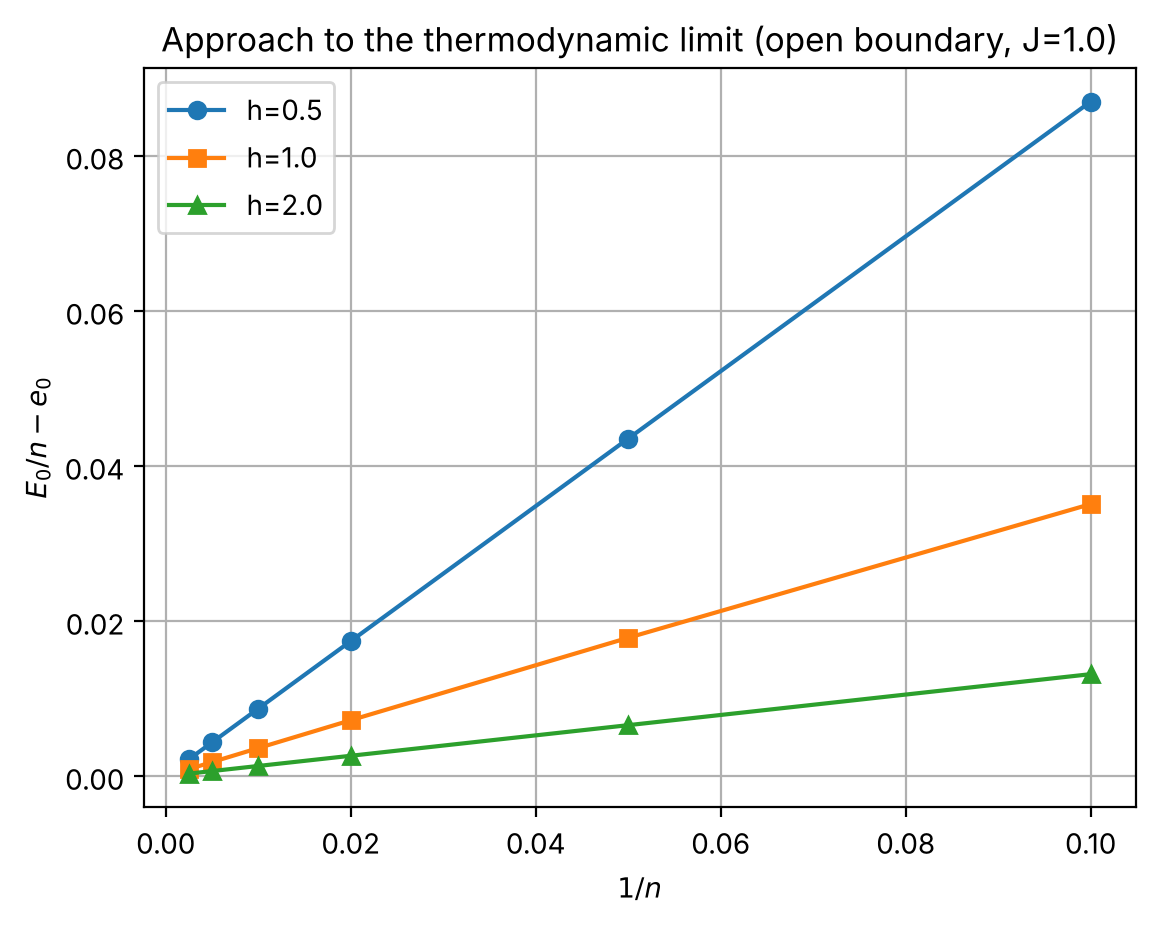

In [3]:
from scipy.integrate import quad

J = 1.0
ns = np.array([10, 20, 50, 100, 200, 400])
for h, mk in [(0.5, "o-"), (1.0, "s-"), (2.0, "^-")]:
    e0_inf = -quad(lambda k: np.sqrt(J**2 + h**2 - 2 * J * h * np.cos(k)), -np.pi, np.pi)[0] / (2 * np.pi)
    e0_n = np.array([ground_energy_jw(n, J, h) / n for n in ns])
    print(f"h={h}: e0(∞) = {e0_inf:.8f},  E0/n (n=400) = {e0_n[-1]:.8f}")
    plt.plot(1 / ns, e0_n - e0_inf, mk, label=f"h={h}")

plt.xlabel("$1/n$")
plt.ylabel(r"$E_0/n - e_0$")
plt.title(f"Approach to the thermodynamic limit (open boundary, J={J})")
plt.legend()
plt.grid()
plt.show()

$E_0/n - e_0$は$1/n$に比例して0に近づく（グラフが原点を通る直線になる）。傾きは開放境界の両端によるエネルギーのずれ（境界エネルギー）を表す。

## 3. VQEとの比較

VQEで$n=6$の$E_0$を求め、層の数$p$を増やしたときの収束を調べる。厳密な$E_0$はJordan-Wigner変換の結果を使う。一様なHVAと局所的なHVAの違いは [04_vqe.ipynb](04_vqe.ipynb)の1節を参照。

E0 (JW) = -6.0776390824


uniform HVA  p=1: E = -5.5474120677  相対誤差 = 8.7e-02
uniform HVA  p=2: E = -5.8385839971  相対誤差 = 3.9e-02
uniform HVA  p=3: E = -5.9585924457  相対誤差 = 2.0e-02
uniform HVA  p=4: E = -6.0264931431  相対誤差 = 8.4e-03


local HVA    p=1: E = -5.5779693855  相対誤差 = 8.2e-02
local HVA    p=2: E = -5.9083229015  相対誤差 = 2.8e-02
local HVA    p=3: E = -6.0776382898  相対誤差 = 1.3e-07
local HVA    p=4: E = -6.0776382871  相対誤差 = 1.3e-07


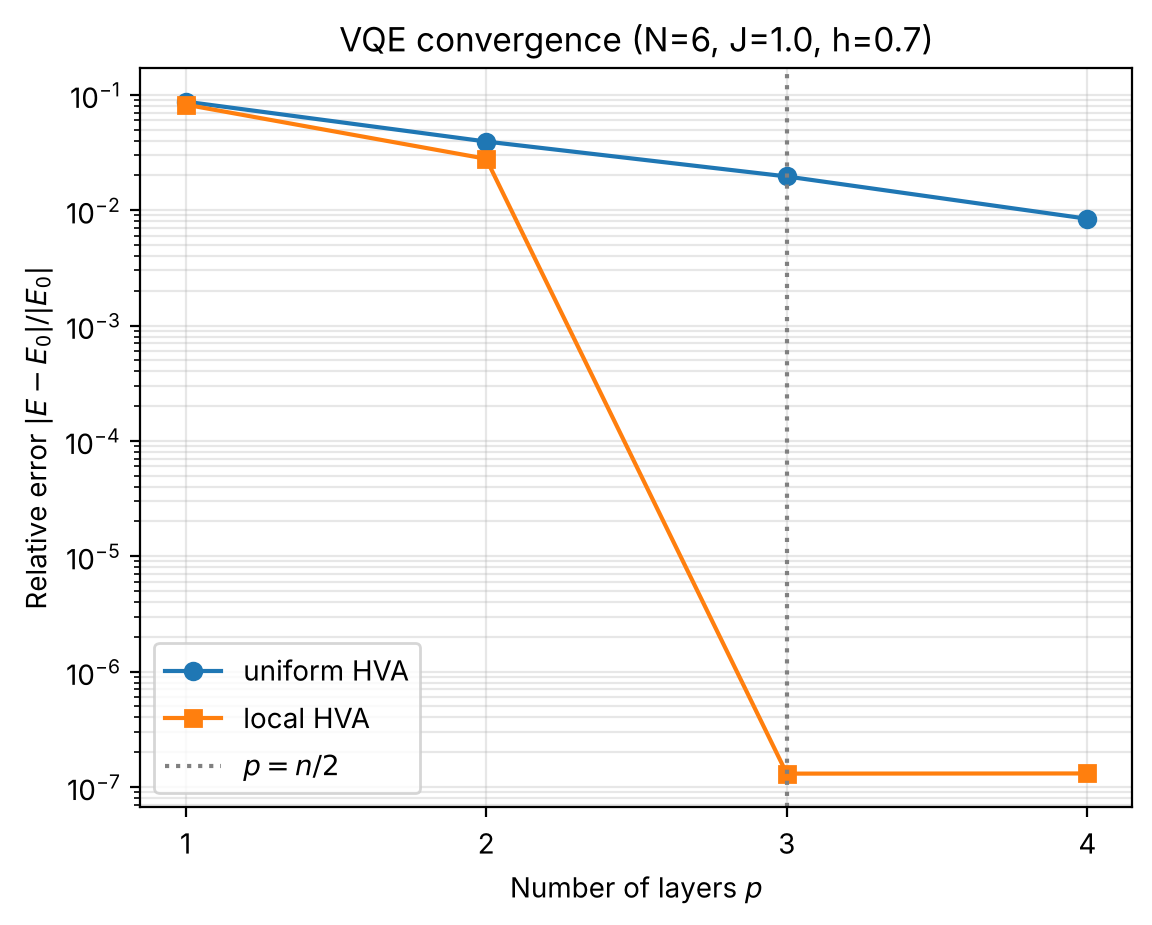

In [4]:
N = 6
J = 1.0
h = 0.7
p_max = 4
E0_exact = ground_energy_jw(N, J, h)
print(f"E0 (JW) = {E0_exact:.10f}")

ps = np.arange(1, p_max + 1)
for local, mk, name in [(False, "o-", "uniform HVA"), (True, "s-", "local HVA")]:
    E_vqe, _ = vqe(N, J, h, p_max, local)
    rel_err = np.abs(E_vqe - E0_exact) / np.abs(E0_exact)
    for p, E, err in zip(ps, E_vqe, rel_err):
        print(f"{name:12s} p={p}: E = {E:.10f}  相対誤差 = {err:.1e}")
    plt.semilogy(ps, np.maximum(rel_err, 1e-16), mk, label=name)

plt.axvline(N / 2, color="gray", ls=":", label=r"$p = n/2$")
plt.xticks(ps)
plt.xlabel("Number of layers $p$")
plt.ylabel(r"Relative error $|E - E_0| / |E_0|$")
plt.title(f"VQE convergence (N={N}, J={J}, h={h})")
plt.legend()
plt.grid(which="both", alpha=0.3)
plt.show()

一様なHVAは$p$を増やすとゆっくり近づくが、なかなか厳密値に届かない。一方、局所的なHVAは$p=3=n/2$層で一気に厳密値（相対誤差は最適化の精度程度）に到達する。

$p=n/2$という数には理由がある。1層の回路は隣のサイトとしか相関を作れないので、$p$層では距離$2p$程度までしか相関が届かない。基底状態は鎖全体にわたる相関を持つので、鎖の端から端（長さ$n$）まで情報が届く$p\approx n/2$層が必要になる。

## まとめ

- 厳密対角化とJordan-Wigner変換の$E_0$は数値誤差の範囲で一致する。Jordan-Wigner変換なら$n=400$でも一瞬で計算でき、熱力学極限の値も確かめられる。
- VQEは、回路の形（アンザッツ）と層の数$p$を適切に選べば厳密値に到達する。今回の開放境界条件では、局所的なHVAで$p=n/2$層が必要だった。